In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import time
import random

In [2]:
def relu(z):
    return np.maximum(np.zeros(z.shape), z)

def relu_gradient(z):
    return np.maximum(np.zeros(z.shape), np.sign(z))

def tanh(z):
    return np.tanh(z)

def tanh_gradient(z):
    return 1 - np.power(tanh(z), 2)

def softmax(z):
    e_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e_z / np.sum(e_z, axis=1, keepdims=True) 

In [3]:
def compute_gradient(w, d, a, grad):
    return np.multiply(d @ w.T, grad(a))

In [4]:
def predict_proba(X, w, b, acti):
    z = X @ w + b
    return acti(z)

In [5]:
def loss(y_true, y_pred):
    epsilon = 1e-15  # Prevent log(0)
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred))

In [6]:
def SGD(X, y, X_valid, y_valid, batch_size=50, interval=5000, l_rate=0.02, epochs=50, acti=relu, dacti=relu_gradient, tol=1e-6):
    indices = np.random.permutation(len(X))
    X_shuff = X[indices]
    Y_shuff = y[indices]

    n, n_features = X.shape
    n_classes = y.shape[1]

    # Initialize weights and bias
    #layer 1 
    w1 = np.random.randn(n_features, n_features) * 0.01
    b1 = np.zeros(n_features)
    #layer 2
    w2 = np.random.randn(n_features, int(n_features/2)) * 0.01
    b2 = np.zeros(int(n_features/2))
    #layer 3 
    w3 = np.random.randn(int(n_features/2), n_classes) * 0.01
    b3 = np.zeros(n_classes)

    losses = []
    losses_valid = []
    acc = []
    acc_valid = []

    # Forward pass
    a1 = predict_proba(X, w1, b1, acti)
    a2 = predict_proba(a1, w2, b2, acti)
    y_pred = predict_proba(a2, w3, b3, softmax)
    a1 = predict_proba(X_valid, w1, b1, acti)
    a2 = predict_proba(a1, w2, b2, acti)
    y_pred_valid = predict_proba(a2, w3, b3, softmax)

    # Compute loss
    losses.append(loss(y, y_pred))
    losses_valid.append(loss(y_valid, y_pred_valid))

    # Compute accuracy
    acc.append(np.mean(np.argmax(y_pred, axis=1) == np.argmax(y, axis=1)))
    acc_valid.append(np.mean(np.argmax(y_pred_valid, axis=1) == np.argmax(y_valid, axis=1)))


    for epoch in range(epochs):
        for i in range(0, n, batch_size):
            X_batch = X_shuff[i:i + batch_size]
            Y_batch = Y_shuff[i:i + batch_size]
            
            # Forward pass
            a1 = predict_proba(X_batch, w1, b1, acti)
            a2 = predict_proba(a1, w2, b2, acti)
            y_pred = predict_proba(a2, w3, b3, softmax)

            # Compute gradients
            d3 = y_pred - Y_batch
            grad_w3 = a2.T @ d3 
            d2 = compute_gradient(w3, d3, a2, dacti)
            grad_w2 = a1.T @ d2
            d1 = compute_gradient(w2, d2, a1, dacti)
            grad_w1 = X_batch.T @ d1

            if (epoch == 5 or epoch == 3):
                l_rate /= 2

            # Update parameters
            w1 -= l_rate * grad_w1
            b1 -= l_rate * np.mean(d1)
            w2 -= l_rate * grad_w2
            b2 -= l_rate * np.mean(d2)
            w3 -= l_rate * grad_w3
            b3 -= l_rate * np.mean(d3)

        # Forward pass
        a1 = predict_proba(X, w1, b1, acti)
        a2 = predict_proba(a1, w2, b2, acti)
        y_pred = predict_proba(a2, w3, b3, softmax)
        a1 = predict_proba(X_valid, w1, b1, acti)
        a2 = predict_proba(a1, w2, b2, acti)
        y_pred_valid = predict_proba(a2, w3, b3, softmax)

        # Compute loss
        losses.append(loss(y, y_pred))
        losses_valid.append(loss(y_valid, y_pred_valid))

        # Compute accuracy
        acc.append(np.mean(np.argmax(y_pred, axis=1) == np.argmax(y, axis=1)))
        acc_valid.append(np.mean(np.argmax(y_pred_valid, axis=1) == np.argmax(y_valid, axis=1)))

        # Check convergence
        if epoch > 10 and abs(losses[-1] - losses[-2]) < tol:
            break

    return w1, b1, w2, b2, w3, b3, losses, losses_valid, acc, acc_valid

In [7]:
with h5py.File('mnist_traindata.hdf5', 'r') as file:
    x_train = file["xdata"][:50000] 
    y_train = file["ydata"][:50000]
    x_valid = file["xdata"][50000:] 
    y_valid = file["ydata"][50000:]
    
with h5py.File('mnist_testdata.hdf5', 'r') as file:
    x_test = file["xdata"][:] 
    y_test = file["ydata"][:]

In [8]:
def run(l_rate, acti, grad):
    t = time.time()
    w1, b1, w2, b2, w3, b3, losses, losses_valid, acc, acc_valid = SGD(x_train, y_train, x_valid, y_valid, 
                                                                       l_rate=0.01, acti=acti, dacti=grad)
    print(f'Traning Time: {time.time()-t}')
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(losses, label='Training Loss')
    plt.plot(losses_valid, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Learning Curves')
    plt.axvline(x=3, color = 'red',label='Learning rate halved')
    plt.axvline(x=5, color = 'red',label='Learning rate halved')
    plt.grid(True)
    plt.legend()
            
    plt.subplot(1, 2, 2)
    plt.plot(acc, label='Training Accuracy')
    plt.plot(acc_valid, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Curves')
    plt.axvline(x=3, color = 'red', label='Learning rate halved')
    plt.axvline(x=5, color = 'red',label='Learning rate halved')
    plt.grid(True)
    plt.legend()
    plt.show()
    
    print(f'Final Training Loss: {losses[-1]}')
    print(f'Final Validation Loss: {losses_valid[-1]}')    
    print(f'Final Training Accuracy: {acc[-1]}')
    print(f'Final Validation Accuracy: {acc_valid[-1]}')

    # Forward pass
    a1 = predict_proba(x_test, w1, b1, relu)
    a2 = predict_proba(a1, w2, b2, relu)
    y_pred = predict_proba(a2, w3, b3, softmax)
    
    # Compute loss
    print(f'Test data Loss = {loss(y_test, y_pred):.4f}')
    
    # Compute accuracy
    print(f'Test data accuracy = {np.mean(np.argmax(y_pred, axis=1) == np.argmax(y_test, axis=1)):.4f}')

ReLU; Learning Rate = 0.01
Traning Time: 205.51900911331177


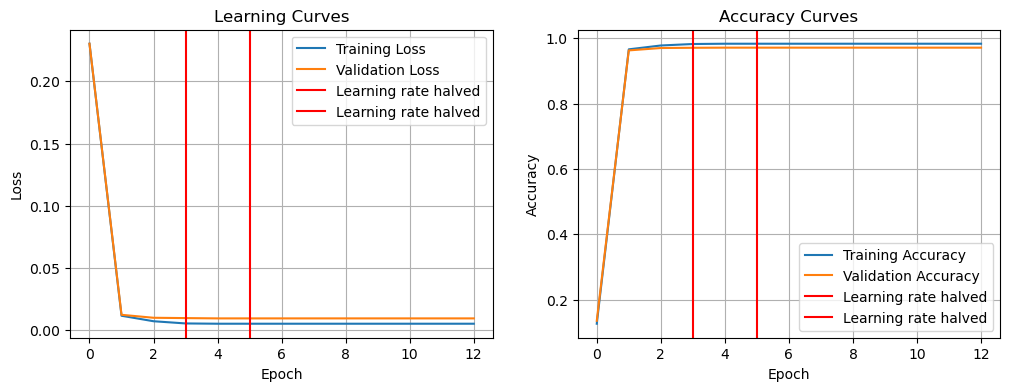

Final Training Loss: 0.005250271958252895
Final Validation Loss: 0.009535811586757406
Final Training Accuracy: 0.98334
Final Validation Accuracy: 0.9713
Test data Loss = 0.0093
Test data accuracy = 0.9726


In [9]:
print("ReLU; Learning Rate = 0.01")
run(0.01, relu, relu_gradient)

ReLU; Learning Rate = 0.05
Traning Time: 176.89448022842407


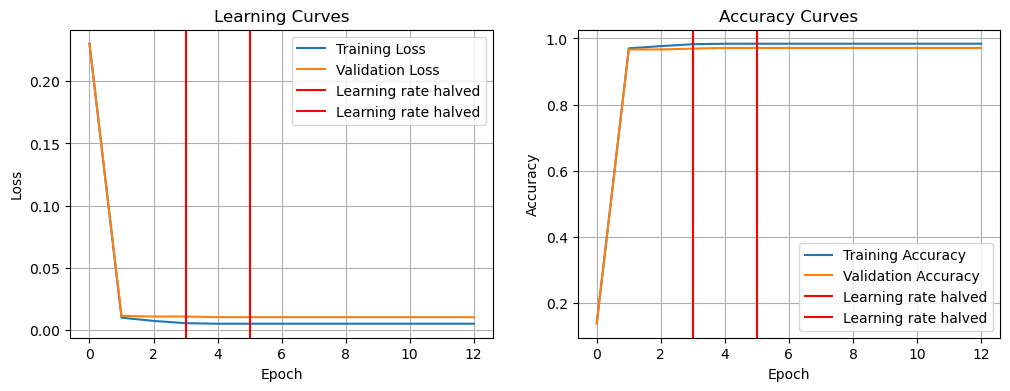

Final Training Loss: 0.004958855714719919
Final Validation Loss: 0.010234416111457818
Final Training Accuracy: 0.98392
Final Validation Accuracy: 0.9712
Test data Loss = 0.0094
Test data accuracy = 0.9726


In [10]:
print("ReLU; Learning Rate = 0.05")
run(0.05, relu, relu_gradient)

ReLU; Learning Rate = 0.1
Traning Time: 177.3202610015869


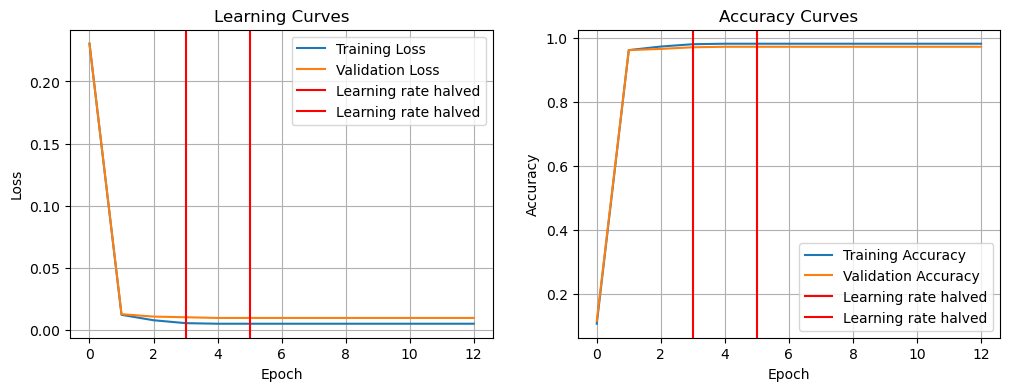

Final Training Loss: 0.005285433701542959
Final Validation Loss: 0.009924685868234279
Final Training Accuracy: 0.98272
Final Validation Accuracy: 0.9732
Test data Loss = 0.0092
Test data accuracy = 0.9711


In [11]:
print("ReLU; Learning Rate = 0.1")
run(0.1, relu, relu_gradient)

tanh; Learning Rate = 0.01
Traning Time: 217.9699831008911


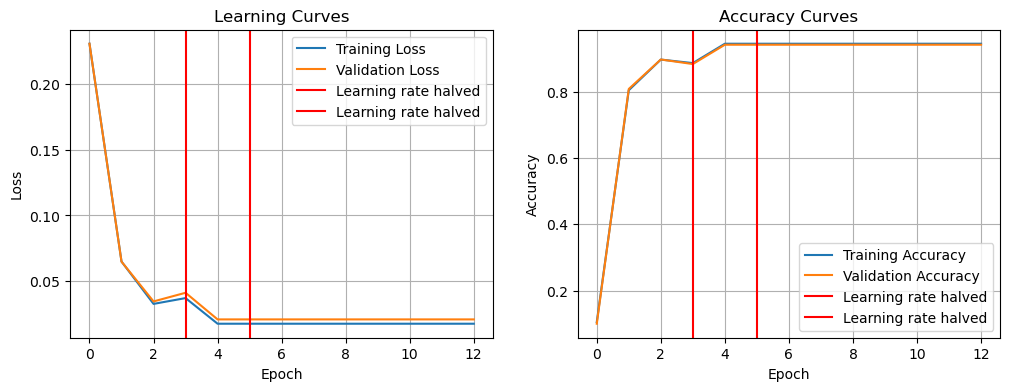

Final Training Loss: 0.017779724483227666
Final Validation Loss: 0.02105915497770634
Final Training Accuracy: 0.94542
Final Validation Accuracy: 0.9424
Test data Loss = 0.1311
Test data accuracy = 0.7192


In [12]:
print("tanh; Learning Rate = 0.01")
run(0.01, tanh, tanh_gradient)

tanh; Learning Rate = 0.05
Traning Time: 201.48947191238403


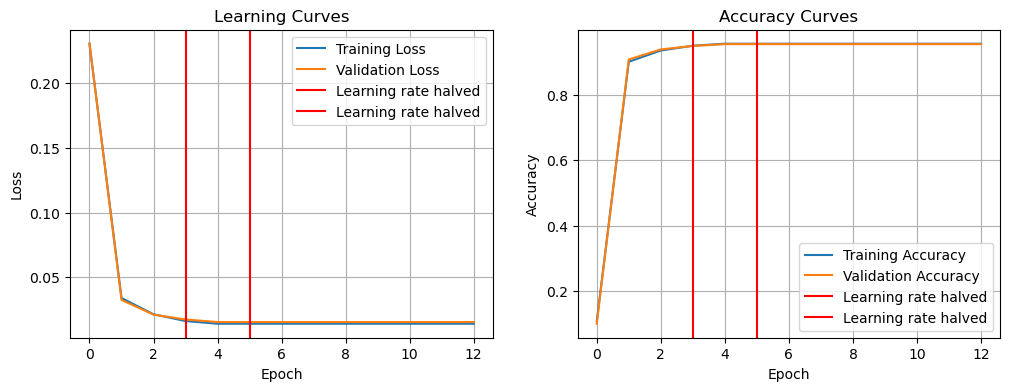

Final Training Loss: 0.01422022354449789
Final Validation Loss: 0.015523596181863586
Final Training Accuracy: 0.95612
Final Validation Accuracy: 0.9549
Test data Loss = 0.3106
Test data accuracy = 0.5795


In [13]:
print("tanh; Learning Rate = 0.05")
run(0.05, tanh, tanh_gradient)

tanh; Learning Rate = 0.1
Traning Time: 183.0871980190277


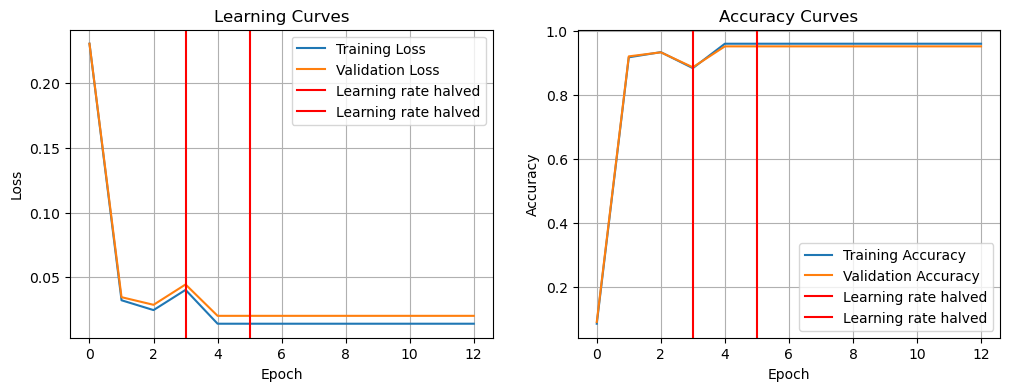

Final Training Loss: 0.014177831941243724
Final Validation Loss: 0.020264439226423254
Final Training Accuracy: 0.95934
Final Validation Accuracy: 0.9511
Test data Loss = 0.6424
Test data accuracy = 0.6663


In [14]:
print("tanh; Learning Rate = 0.1")
run(0.1, tanh, tanh_gradient)

Input Layer $= 784\text{ Nodes}$\
Input Layer $= 392\text{ Nodes}$\
Input Layer $= 392\text{ Nodes}$\
Output Layer $= 10\text{ Nodes}$\
The Best Performing network is ReLU Hidden Layer Activation with Learning Rate $= 0.1$.\
Testing accuracy $= 97.11 \%$